# Social dimensions of Eaton and Palisades fires
## Week 8 Discussion section

In [48]:
import os
import matplotlib.pyplot as plt
import contextily as cx
import pandas as pd
import geopandas as gpd

## 1. Metadata exploration

In [7]:
# Load eji dictionary
eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')

In [13]:
print(eji_dictionary.shape)
eji_dictionary.head()

(170, 8)


,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (FIPS) code,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Boundary files\n\nhttps://www.census.gov/geographies/ \nmapping-files/time-...,No Value,No Value
3,AFFGEOID,AFFGEOID,"Census tract identifier; a concatenation of current state Federal Information Processing Series (FIPS) code, county ...",No Value,No Value,No Value,No Value,No Value
4,GEOID,GEOID,"11-digit census tract identifier, which is a concatenation of the 2-digit state FIPS code, 3-digit county FIPS code,...",No Value,No Value,No Value,"2020 State FIPS + 2020 County FIPS + 2020 Census Tract Code (All States, except Connecticut)\nFor Connecticut tracts...",Connecticut tracts are using updated 2022 County FIPS codes. All other tracts are using 2020 FIPS codes.


In [11]:
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip() # Remove leading/lagging spaces

pd.set_option('display.max_colwidth', 120) # Display up to 120 characters
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


### What are some variables that may impact fire response?
- E_POV200
- E_RENTER
- E_HOUBDN
- E_DISABL

## 2. Polygon Intersection

In [22]:
# Import fire perimeters
fp = os.path.join('data', 'Palisades_Perimieter_20250121', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(fp)

fp = os.path.join('data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp)

perimeters = pd.concat([palisades, eaton])
perimeters

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.51987 34.02991, -118.52001 34.02989, -118.52013 34.02993, -118.52024 34.03..."
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.10089 34.16679, -118.10086 34.16679, -118.10085 34.16677, -118.10083 34.16..."


In [52]:
# Import EJI Data
eji = gpd.read_file('data/EJI_2024_California/EJI_2024_California.gdb')
eji.shape

(9109, 174)

In [53]:
# Reproject crs to match perimeter data
eji = eji.to_crs(4269)
eji.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [70]:
# Spatially join
palisades_join = gpd.sjoin(eji, palisades, how='inner', predicate='intersects')
print(f"Census tracts Intersecting the Palisades fire perimeter:{palisades_eji.shape}")

Census tracts Intersecting the Palisades fire perimeter:(15, 198)


<Axes: >

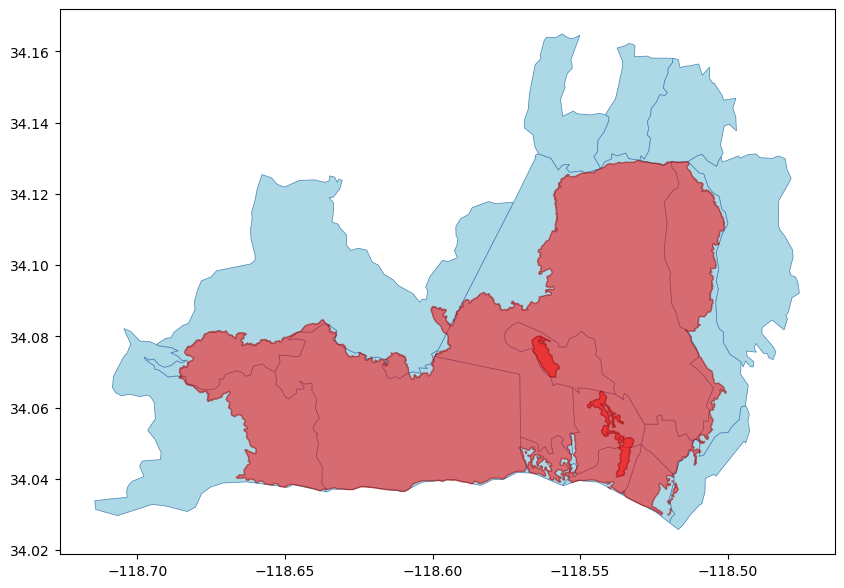

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(10,10))
palisades_join.plot(ax=ax, color='lightblue', edgecolor='steelblue', linewidth=0.5
                   
                  )
palisades.plot(ax=ax, alpha=0.5, color='red', edgecolor='darkred')

In [74]:
# Spatially join eaton
eaton_join = gpd.sjoin(eji, eaton, how='inner', predicate='intersects')
print(f"Census tracts Intersecting the Eaton fire perimeter:{eaton_eji.shape}")

Census tracts Intersecting the Eaton fire perimeter:(18, 198)


<Axes: >

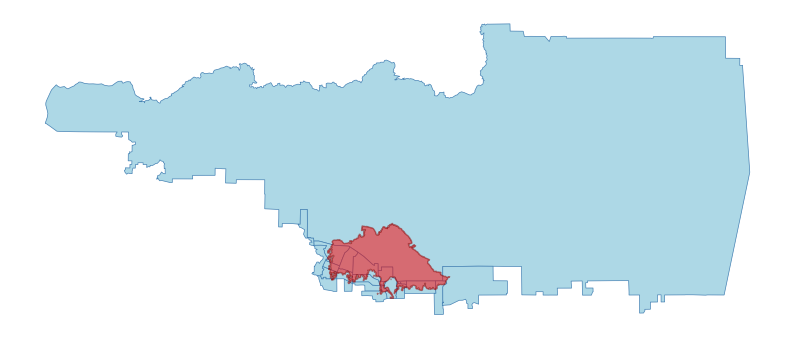

In [83]:
fig, ax = plt.subplots(1, 1, figsize=(10,10))
eaton_join.plot(ax=ax, color='lightblue', edgecolor='steelblue', linewidth=0.5)
ax.axis('off')
eaton.plot(ax=ax, alpha=0.5, color='red', edgecolor='darkred')

## 3. Polygon clipping

In [76]:
palisades_clip = eji.clip(palisades)

<Axes: >

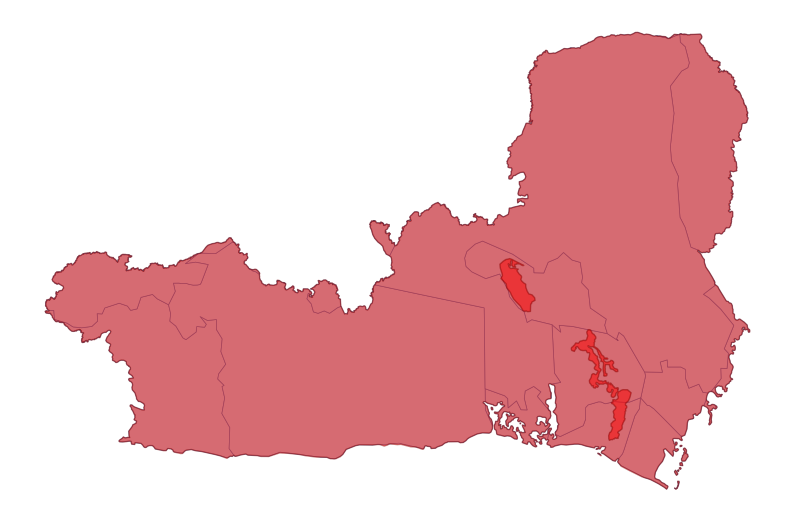

In [82]:
fig, ax = plt.subplots(1, 1, figsize=(10,10))
palisades_clip.plot(ax=ax, color='lightblue', edgecolor='steelblue', linewidth=0.5)
ax.axis('off')
palisades.plot(ax=ax, alpha=0.5, color='red', edgecolor='darkred')

In [78]:
eaton_clip = eji.clip(eaton)

<Axes: >

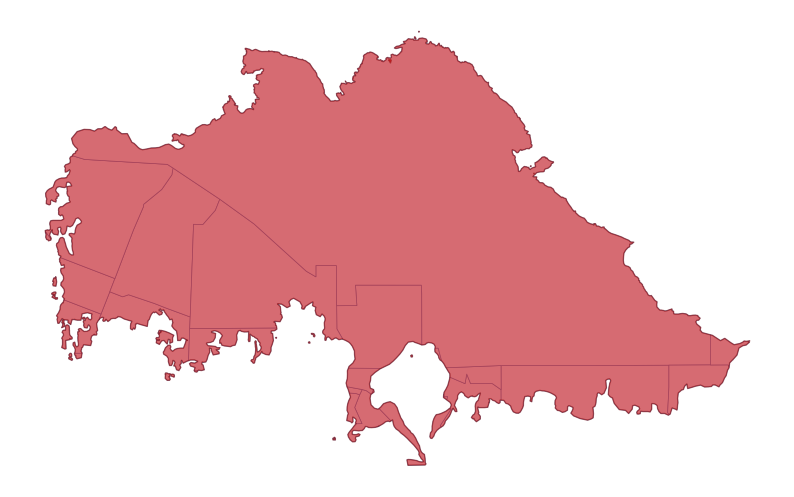

In [81]:
fig, ax = plt.subplots(1, 1, figsize=(10,10))
eaton_clip.plot(ax=ax, color='lightblue', edgecolor='steelblue', linewidth=0.5)
ax.axis('off')
eaton.plot(ax=ax, alpha=0.5, color='red', edgecolor='darkred')

## 4. Visualize fire perimeters with a basemap

NameError: name 'UPDATE' is not defined

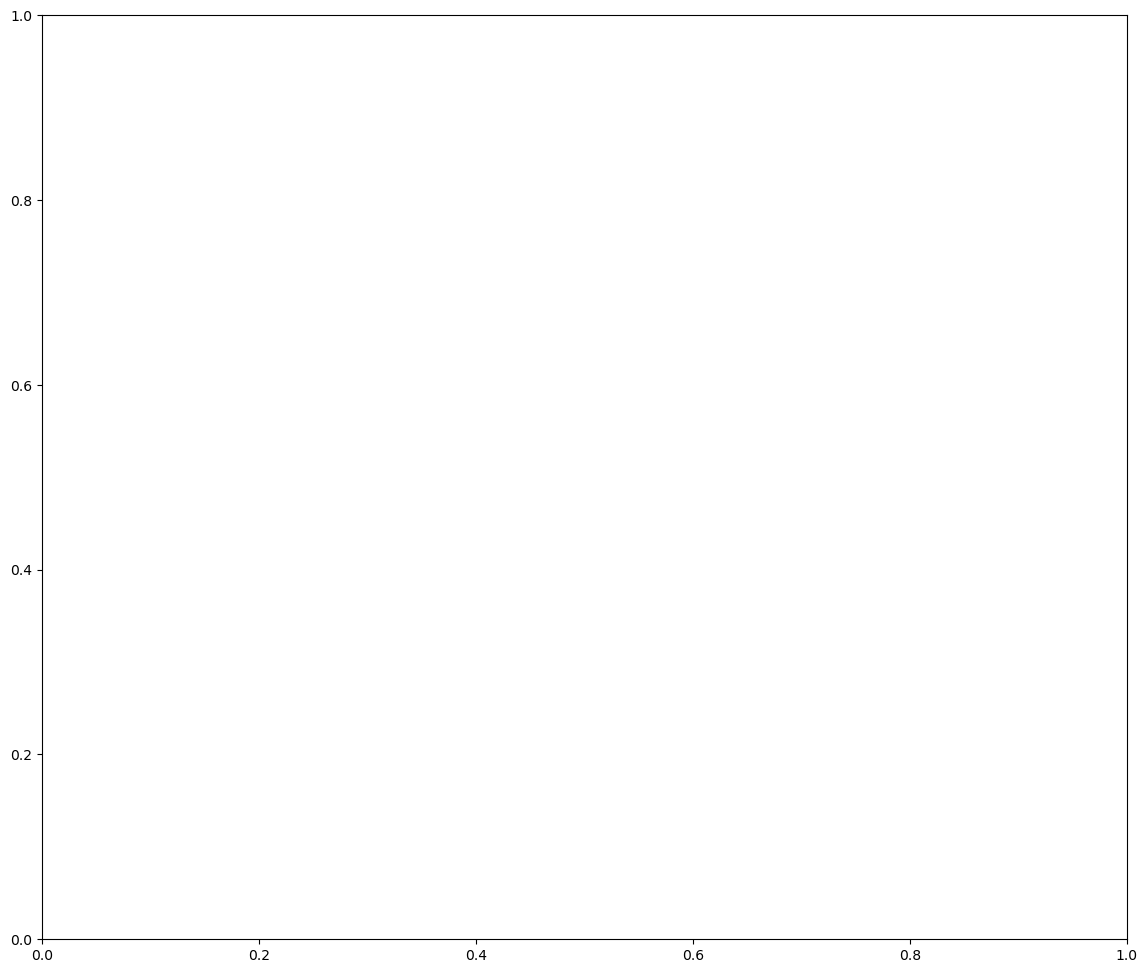

In [69]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# ADD FIRE PERIMETERS: UPDATE FILL TRANSPARENCY AND COLOR

# ADD LEGEND OR ANNOTATION TO IDENTIFY EACH FIRE

# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
cx.add_basemap(ax, crs=UPDATE.crs, source=cx.providers.Esri.WorldStreetMap)

# ADD TITLE

ax.axis('off')

plt.tight_layout()
plt.show()